##Train 2.124 / dev 2.151. Still slightly underfit. Next: Day 2, neural bigram, then lecture 4.

In [185]:
import torch
import random
import torch.nn.functional as F

In [186]:
names = open('names.txt').read().splitlines()
characters = ['.']+sorted(set(''.join(names)))
stoi = {s:i for i,s in enumerate(characters)}
itos = {i:s for s,i in stoi.items()}

In [187]:
block_size = 3
x,y = [],[]
for name in names:
    context = [0]*block_size
    for ch in name+'.':
      idx = stoi[ch]
      x.append(context)
      y.append(idx)
      context = context[1:]  + [idx]

x = torch.tensor(x)
y = torch.tensor(y)

In [188]:
y.shape

torch.Size([228146])

In [189]:
x.shape

torch.Size([228146, 3])

In [190]:
def build_dataset(names):
  block_size = 3
  x,y = [],[]
  for name in names:
    context = [0]*block_size
    for ch in name+'.':
      idx = stoi[ch]
      x.append(context)
      y.append(idx)
      context = context[1:]  + [idx]

  x = torch.tensor(x)
  y = torch.tensor(y)

  return x,y

In [191]:
random.seed(42)
random.shuffle(names)
n1 = int(0.8 * len(names))
n2 = int(0.9 * len(names))
Xtr, Ytr = build_dataset(names[:n1])
Xdev, Ydev = build_dataset(names[n1:n2])
Xte, Yte = build_dataset(names[n2:])

In [192]:
torch.manual_seed(32)
C = torch.randn(27,2) #Random Wieght Matrix(Embedding) 27 for 27 chars and 2 is some dimension

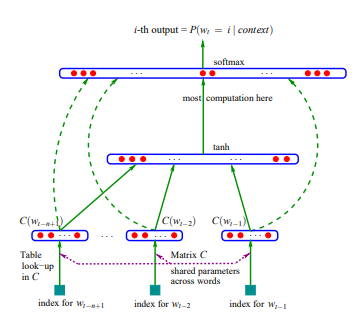

Layer 01 : Now what we want is to use this lookup table C for every character example of x

In [193]:
torch.manual_seed(32)
emb = C[x]
W1 = torch.randn(6,100)
b1 = torch.randn(100)
h = emb.view(-1,6) @ W1 + b1

Layer 02 : Applying tanh()

In [194]:
torch.manual_seed(32)
W2 = torch.randn(100,27)
b2 = torch.randn(27)
logits = torch.tanh(h) @ W2 + b2

Layer 03 : Applying Softmax()

In [195]:
parameters = [C,W1,b1,W2,b2]
no_of_params = 0
for p in parameters:
  p.requires_grad = True
  no_of_params+=p.nelement()

In [196]:
torch.tensor(32)

tensor(32)

In [197]:
torch.manual_seed(32)
counts = logits.exp()
probs = counts/counts.sum(1,keepdim=True) #Rows of this matrix are the probability distributions across 27 classes(alphabets as next characters)
loss = -probs[torch.arange(228146),y].log().mean()
loss

tensor(12.5308)

Now we'll try and reduce the loss as much as possible by training the whole neural net

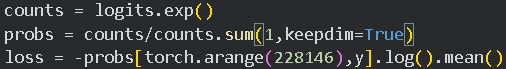

These 3 lines can be replaced by a single Cross Entropy Loss

In [198]:
g = torch.Generator().manual_seed(32)
C  = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 300), generator=g) * 0.2
b1 = torch.randn(300, generator=g) * 0.01
W2 = torch.randn((300, 27), generator=g) * 0.01
b2 = torch.zeros(27)
parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

In [199]:
emb = C[Xtr[:32]]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
loss = F.cross_entropy(h @ W2 + b2, Ytr[:32])
print(loss.item())

3.323559522628784


In [200]:
lossi = []
steps = 30000
epochs = []

for k in range(steps):
    ix = torch.randint(0, Xtr.shape[0], (32,))
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])

    for p in parameters:
        p.grad = None
    loss.backward()

    lr = 0.1 * (1 - k / steps) + 0.005 * (k / steps) if k < 20000 else 0.01      # step decay
    for p in parameters:
        p.data += -lr * p.grad

    lossi.append(loss.item())
    epochs.append(k)

print('train loss : ',loss.item())

train loss :  1.73741614818573


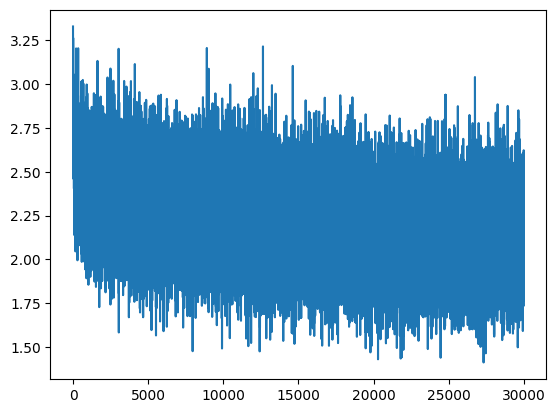

In [203]:
import matplotlib.pyplot as plt

plt.plot(epochs,lossi)

In [204]:
@torch.no_grad()
def split_loss(X, Y):
    emb = C[X]
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
    logits = h @ W2 + b2
    return F.cross_entropy(logits, Y).item()

print('train', split_loss(Xtr, Ytr))
print('dev  ', split_loss(Xdev, Ydev))

train 2.124159574508667
dev   2.150569438934326
